(pool-cells)=
# Pool cells into pseudobulk profiles

Tests of conditions compare samples, so the cells of every sample and cell type are
first pooled into one profile ([Why pseudobulk](../why_pseudobulk.ipynb)). A cube keeps
those profiles: for every gene, sums over the cells of each sample and cell type, with
the number of cells pooled into each. Because every value is a sum, cell types can be
merged and samples pooled later without the cells, and the same sums give what
describes the cells: the fraction that express each gene and their mean expression, the
values of a dot plot. This page pools the cells of the simulated PBMC
study (the `simulated_pbmc` dataset of the [Datasets](../reference/datasets.md) page),
looks at the markers of its cell types and at its samples, and merges a rare cell type
into its lineage. [The cube and its additive layers](../statistics/cubes.md) defines
every layer.

## Samples, cell types and layers

{api}`from_cells` takes a cells x genes matrix of counts and the sample and the cell
type of every cell. A sample table, with a `sample_id` for every sample label, sets the
order of the samples and carries the variables that designs use, here the donor and the
condition; a group table does the same for the cell types, and may carry their lineage.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse

import cytepool
from cytepool.cube import from_cells
from cytepool.plotting import plot_cell_numbers, plot_dotplot, plot_pca

cells = np.load("simulated_pbmc_cells.npz")
counts = scipy.sparse.csr_array(
    (cells["data"], cells["indices"], cells["indptr"]), shape=tuple(cells["shape"])
)
sample_ids = np.unique(cells["cell_sample"])
cube = from_cells(
    counts,
    samples=cells["cell_sample"],
    groups=cells["cell_type"],
    sample_table={
        "sample_id": sample_ids,
        "donor": [sample.split("_")[0] for sample in sample_ids],
        "condition": [sample.split("_")[1] for sample in sample_ids],
    },
    group_table={
        "group_id": cells["cell_types"],
        "lineage": ["lymphoid"] * 4 + ["myeloid"] * 2,
    },
    features=cells["feature_id"],
)
print(f"CytePool {cytepool.__version__}")
print(cube)
print(cube.groups)

CytePool 0.1.dev61+g194f49f8f
Cube with 24 samples x 6 groups x 2,000 features
  layers: counts (uint32), detected (uint32), log_sum (float64), log_sum_sq (float64), linear_sum (float64)
  filled: 144 of 144 sample x group entries have cells (100.0%)
  samples: sample_id, donor, condition
  groups: group_id, lineage
  features: feature_id
Table with 6 rows and 2 columns
  group_id         lineage
  str              str
  B cells          lymphoid
  CD4 T cells      lymphoid
  CD8 T cells      lymphoid
  NK cells         lymphoid
  Monocytes        myeloid
  Dendritic cells  myeloid


The cube holds five layers: the `counts`, which the tests read, and four that describe
the cells: `detected`, the number of cells with a positive count, and the sums of the
cells' log-normalized values (`log_sum`), of their squares (`log_sum_sq`) and of the
normalized values themselves (`linear_sum`). Each cell is normalized to 10,000 counts
and log-transformed, as scanpy's `normalize_total` and `log1p` do.

## The markers of each cell type

A dot plot shows, for chosen genes and cell types, the fraction of the cells that
express each gene, as the area of a dot, and their mean expression, as its colour, as
scanpy draws it [@wolf2018]. {api}`plot_dotplot` reads both from the cube, pooled over
every sample, and gives the values scanpy computes from the cells
([Validation](../validation.md#principal-components-and-dot-plots)). The simulation
gave each cell type 20 marker genes; here are three of each, with the means of each
gene scaled from 0 to 1 over the cell types, as scanpy's `standard_scale="var"` scales
them.

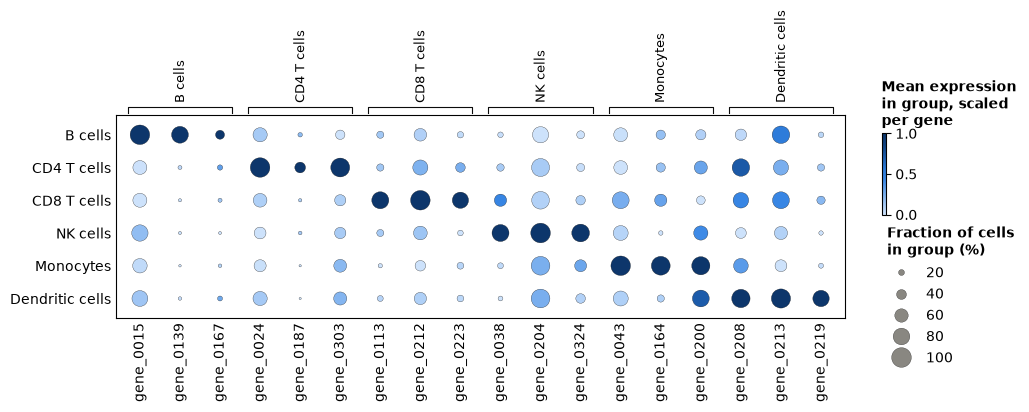

In [2]:
markers = {
    cell_type: list(genes[:3])
    for cell_type, genes in zip(cells["cell_types"], cells["marker_genes"])
}
ax = plot_dotplot(cube, markers, standard_scale="gene")
plt.show()

Each cell type's markers are expressed in more of its cells, and more highly, than in
the other cell types, as an annotation that is right shows them. A cell type whose
markers light up in another row is worth a second look before any test.

## What changes in the cells

{api}`Cube.collapse_samples` pools the samples that share a value of a sample column,
here the condition: the profiles of the 12 control samples are summed into one, and so
are those of the 12 stimulated ones. From the pooled sums, {api}`Cube.fraction_detected`,
{api}`Cube.mean` and {api}`Cube.variance` give the fraction of the cells that detect
each gene, and the mean and the variance of their log-normalized values. For one gene
of the response program that the simulation gave every cell type:

In [3]:
by_condition = cube.collapse_samples("condition")
print(by_condition.samples)

gene = cube.features["feature_id"].tolist().index("gene_0191")
detected = by_condition.fraction_detected()[:, :, gene]
mean = by_condition.mean()[:, :, gene]
variance = by_condition.variance()[:, :, gene]
print(f"\ngene_0191, control -> stimulated{'detected':>12}{'mean':>16}{'variance':>16}")
for g, cell_type in enumerate(by_condition.groups["group_id"]):
    print(
        f"{cell_type:<32}{detected[g, 0]:>6.2f} -> {detected[g, 1]:.2f}"
        f"{mean[g, 0]:>8.2f} -> {mean[g, 1]:.2f}{variance[g, 0]:>8.2f} -> {variance[g, 1]:.2f}"
    )

Table with 2 rows and 3 columns
  sample_id  condition  n_pooled_samples
  str        str        int64
  ctrl       ctrl       12
  stim       stim       12

gene_0191, control -> stimulated    detected            mean        variance
B cells                           0.86 -> 1.00    1.98 -> 3.44    0.90 -> 0.43
CD4 T cells                       0.78 -> 0.99    1.59 -> 3.26    0.92 -> 0.48
CD8 T cells                       0.85 -> 0.99    1.87 -> 3.50    0.91 -> 0.49
NK cells                          0.74 -> 0.97    1.49 -> 2.89    0.98 -> 0.64
Monocytes                         0.65 -> 0.97    1.20 -> 2.88    0.92 -> 0.60
Dendritic cells                   0.75 -> 0.96    1.53 -> 2.78    0.97 -> 0.82


After the stimulation nearly every cell of every type expresses the gene, and the mean
of their log-normalized values about doubles. These pooled values describe the cells;
they are no test, since the samples pooled are the replicates a test needs ([Genes that
change in each cell type](genes_per_cell_type.ipynb) tests the change). Pooling the
samples of each donor, `collapse_samples("donor")`, gives one profile per donor, for
questions about donors ([Repeated measures and donors](repeated_measures.ipynb)).

## The samples of each cell type

DESeq2's PCA plot places the samples of one cell type on the principal components of
their 500 most variable genes [@love2014], prepared as for an MDS plot: profiles of
fewer than 10 cells are left out, genes are filtered by expression, and the values are
log-CPM ({api}`plot_pca`, {api}`principal_components`). It shows at a glance whether
the samples group as the design expects.

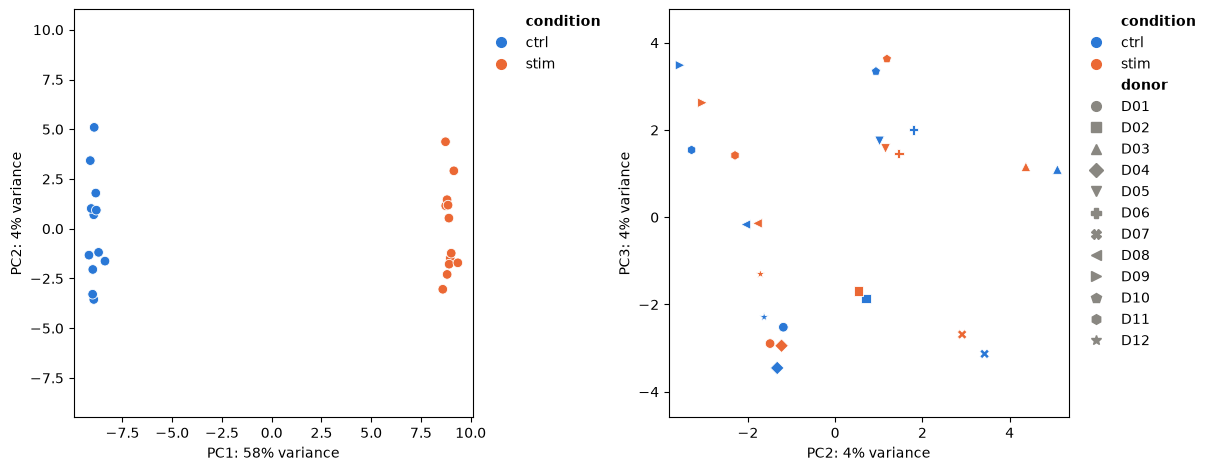

In [4]:
figure, (left, right) = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
plot_pca(cube, group="Monocytes", color_by="condition", ax=left)
plot_pca(
    cube,
    group="Monocytes",
    color_by="condition",
    marker_by="donor",
    components=(2, 3),
    ax=right,
)
plt.show()

The first component, more than half of the variance, is the stimulation. On the second
and third, each donor's two samples lie near each other: donors differ, which is why
the design of [Genes that change in each cell type](genes_per_cell_type.ipynb) pairs
them.

## A cell type with few cells

Six profiles of dendritic cells pool fewer than 10 cells, and {api}`limma_voom` leaves
them out of the dendritic cells' fit ([Quick start](../quickstart.ipynb)). Where a rare
cell type matters less than its lineage, {api}`Cube.regroup` merges it with related
cell types: every layer of the merged cell type is the sum of its members', as pooling
the relabelled cells would give. Here the group table's lineage names the myeloid cell
types ({api}`Table.filter`).

Table with 5 rows and 2 columns
  group_id       lineage
  str            str
  B cells        lymphoid
  CD4 T cells    lymphoid
  CD8 T cells    lymphoid
  NK cells       lymphoid
  Myeloid cells  myeloid


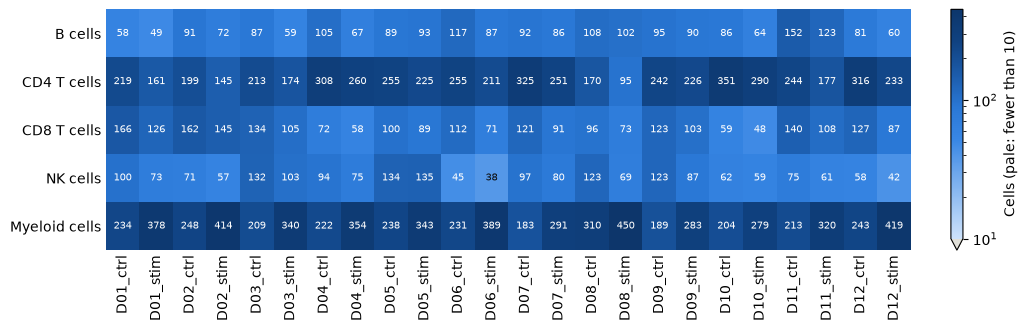

In [5]:
myeloid = cube.groups.filter(cube.groups["lineage"] == "myeloid")["group_id"]
merged = cube.regroup({"Myeloid cells": list(myeloid)})
print(merged.groups)
plot_cell_numbers(merged)
plt.show()

Every profile of the merged myeloid cells holds enough cells. The merged profile mixes
two cell types in proportions that differ between samples, and the stimulation changes
those proportions ([Cell-type composition](composition.ipynb)), so a change in the
merged profile can come from either; testing the monocytes alone, and the dendritic
cells on their 18 profiles, keeps the two apart.

## Choices

- **Samples.** A sample is a biological replicate: one donor in one condition, or one
  tissue of a donor. Pool technical replicates, such as lanes or libraries of the same
  sample, by giving them one sample label, or later with {api}`Cube.collapse_samples`.
- **Tables.** The sample and group tables take a pandas DataFrame or a mapping of
  columns, and a cube keeps them as {api}`Table` objects: {api}`Table.select` keeps some
  columns, {api}`Table.filter` some rows, {api}`Table.with_columns` adds columns, such
  as a variable for a design, and {api}`Table.to_pandas` gives a DataFrame.
- **Cell types.** Annotate at the level the question needs. {api}`Cube.select` keeps
  some cell types, {api}`Cube.regroup` merges them, and the minimum of cells
  (`min_cells` of {api}`limma_voom`, 10 by default) leaves out the profiles of too few
  cells, with the reason in the result.
- **Layers.** `layers="counts"` keeps only what the tests read: 4 bytes per sample,
  cell type and gene, against 32 for all five layers, which matters for atlases of
  thousands of samples. The dot plot needs `detected` and `log_sum`, and
  {api}`Cube.variance` needs `log_sum_sq`.
- **Normalization of the cells.** `target_sum` (10,000) sets the total that every cell
  is scaled to, and `library_sizes` gives the totals when the matrix holds only some of
  the genes.
- **Bulk data.** {api}`from_bulk` wraps a samples x genes matrix of counts as a cube
  with one group, which every test of a cube takes ([Bulk RNA-seq](bulk_rna_seq.ipynb)).
- **Other tools.** Cells in an AnnData, and profiles pooled by scanpy, decoupler or
  LIANA, become cubes too ([Work with AnnData and MuData](anndata_and_mudata.ipynb)).